In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from PIL import Image
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## ResNet-UNet Architecture
U-Net with a ResNet encoder (ImageNet-pretrained by default) and a U-Net decoder with transposed-conv upsampling, skip connections and dropout.

In [2]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_rate=0.15, use_dropout=True):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if use_dropout:
            layers.append(nn.Dropout2d(dropout_rate))

        layers.extend([
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ])
        if use_dropout:
            layers.append(nn.Dropout2d(dropout_rate))

        self.double_conv = nn.Sequential(*layers)

    def forward(self, x):
        return self.double_conv(x)

# (constructor, ImageNet weights enum name, channels of [stem, layer1, layer2, layer3, layer4])
RESNET_CFG = {
    'resnet18':  (models.resnet18,  'ResNet18_Weights',  [64, 64, 128, 256, 512]),
    'resnet34':  (models.resnet34,  'ResNet34_Weights',  [64, 64, 128, 256, 512]),
    'resnet50':  (models.resnet50,  'ResNet50_Weights',  [64, 256, 512, 1024, 2048]),
    'resnet101': (models.resnet101, 'ResNet101_Weights', [64, 256, 512, 1024, 2048]),
}

class ResNetUNet(nn.Module):
    """U-Net with a ResNet encoder.

    Encoder (strides relative to the input):
        stem   (conv7x7 + BN + ReLU)  /2
        layer1 (after maxpool)        /4
        layer2                        /8
        layer3                        /16
        layer4 (bottleneck)           /32
    Decoder: ConvTranspose2d x2 + skip concat + DoubleConv, five times, back to full resolution.
    Input height/width must be divisible by 32 (256x256 is fine).
    """
    def __init__(self, backbone='resnet34', pretrained=True, in_ch=3, out_ch=1,
                 dropout_rates=None):
        super().__init__()
        if backbone not in RESNET_CFG:
            raise ValueError(f"backbone must be one of {list(RESNET_CFG)}")

        if dropout_rates is None:
            dropout_rates = {
                'encoder': {'layer3': 0.15, 'layer4': 0.2},   # same idea as U-Net: enc4 = 0.15, bottleneck = 0.2
                'decoder': 0.15,
            }
        self.dropout_rates = dropout_rates

        ctor, weights_name, ch = RESNET_CFG[backbone]
        weights = getattr(models, weights_name).IMAGENET1K_V1 if pretrained else None
        backbone_net = ctor(weights=weights)

        # Optional: support in_ch != 3 by rebuilding the first conv
        if in_ch != 3:
            backbone_net.conv1 = nn.Conv2d(in_ch, 64, kernel_size=7, stride=2, padding=3, bias=False)

        # Encoder
        self.stem = nn.Sequential(backbone_net.conv1, backbone_net.bn1, backbone_net.relu)  # /2
        self.pool = backbone_net.maxpool                                                    # /4
        self.layer1 = backbone_net.layer1
        self.layer2 = backbone_net.layer2
        self.layer3 = backbone_net.layer3
        self.layer4 = backbone_net.layer4

        self.drop3 = nn.Dropout2d(dropout_rates['encoder']['layer3'])
        self.drop4 = nn.Dropout2d(dropout_rates['encoder']['layer4'])

        c0, c1, c2, c3, c4 = ch
        d = dropout_rates['decoder']

        # Decoder
        self.up4 = nn.ConvTranspose2d(c4, c3, kernel_size=2, stride=2)       # /32 -> /16
        self.dec4 = DoubleConv(c3 * 2, c3, d, use_dropout=True)
        self.up3 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)       # /16 -> /8
        self.dec3 = DoubleConv(c2 * 2, c2, d, use_dropout=True)
        self.up2 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)       # /8  -> /4
        self.dec2 = DoubleConv(c1 * 2, c1, d, use_dropout=True)
        self.up1 = nn.ConvTranspose2d(c1, c0, kernel_size=2, stride=2)       # /4  -> /2
        self.dec1 = DoubleConv(c0 * 2, c0, d, use_dropout=True)
        self.up0 = nn.ConvTranspose2d(c0, 32, kernel_size=2, stride=2)       # /2  -> full res
        self.dec0 = DoubleConv(32, 32, d, use_dropout=True)

        self.final_conv = nn.Conv2d(32, out_ch, kernel_size=1)

    def forward(self, x):
        # Encoder
        e0 = self.stem(x)                       # /2
        e1 = self.layer1(self.pool(e0))         # /4
        e2 = self.layer2(e1)                    # /8
        e3 = self.drop3(self.layer3(e2))        # /16
        b = self.drop4(self.layer4(e3))         # /32 (bottleneck)

        # Decoder
        d4 = self.dec4(torch.cat([self.up4(b), e3], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e0], dim=1))
        d0 = self.dec0(self.up0(d1))

        return self.final_conv(d0)


## Dataset and Data Loading

In [3]:
IMG_EXTS = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

def find_pv01_pairs(root_dir):
    """Walk root_dir and pair every 'NAME.<ext>' image with its 'NAME_label.<ext>' mask.
    Returns {group_name: [(image_path, label_path), ...]} where group_name is the
    rooftop folder (PV01_Rooftop_Brick, PV01_Rooftop_FlatConcrete, ...)."""
    groups = {}
    for folder, _, files in sorted(os.walk(root_dir)):
        by_stem = {os.path.splitext(f)[0]: f for f in sorted(files) if f.lower().endswith(IMG_EXTS)}
        rel = os.path.relpath(folder, root_dir)
        group = rel.split(os.sep)[0]
        for stem, fname in by_stem.items():
            if stem.endswith('_label'):
                continue
            lbl = by_stem.get(stem + '_label')
            if lbl is not None:
                groups.setdefault(group, []).append((os.path.join(folder, fname), os.path.join(folder, lbl)))
    return groups

def build_pv01_splits(root_dir, val_frac=0.15, test_frac=0.15, seed=42):
    """PV01 ships without a train/val/test split, so make a fixed, seeded one.
    The split is done per rooftop folder so all three types appear in every split."""
    groups = find_pv01_pairs(root_dir)
    assert len(groups) > 0, f"No image/_label pairs found under {root_dir}"
    rng = np.random.RandomState(seed)
    train, val, test = [], [], []
    for g in sorted(groups):
        pairs = groups[g]
        idx = rng.permutation(len(pairs))
        n_test = int(round(len(pairs) * test_frac))
        n_val = int(round(len(pairs) * val_frac))
        test += [pairs[i] for i in idx[:n_test]]
        val += [pairs[i] for i in idx[n_test:n_test + n_val]]
        train += [pairs[i] for i in idx[n_test + n_val:]]
        print(f"{g}: {len(pairs)} pairs")
    return train, val, test

class PV01Dataset(Dataset):
    def __init__(self, pairs, transform=None, img_size=(256, 256)):
        self.pairs = pairs
        self.transform = transform
        self.img_size = img_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, label_path = self.pairs[idx]

        img = Image.open(img_path).convert('RGB').resize(self.img_size)
        label = Image.open(label_path).convert('L').resize(self.img_size, Image.NEAREST)

        if self.transform:
            img = self.transform(img)
        else:
            img = transforms.ToTensor()(img)

        # binary mask: any non-zero pixel is solar panel (works for 0/255 and 0/1 masks)
        label = torch.from_numpy((np.array(label) > 0).astype(np.float32)).unsqueeze(0)

        return img, label


## Loss Functions and Metrics

In [4]:
def dice_coef(pred, target, smooth=1e-6):
    pred = pred.contiguous()
    target = target.contiguous()
    intersection = (pred * target).sum(dim=(2,3))
    denom = pred.sum(dim=(2,3)) + target.sum(dim=(2,3))
    dice = (2. * intersection + smooth) / (denom + smooth)
    return dice.mean()

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        dice = dice_coef(pred, target, smooth=self.smooth)
        return 1.0 - dice

def combined_loss(logits, mask, bce_weight=0.6, dice_weight=0.4):
    bce_loss = nn.BCEWithLogitsLoss()
    bce = bce_loss(logits, mask)
    probs = torch.sigmoid(logits)
    dice = DiceLoss()(probs, mask)
    return bce_weight * bce + dice_weight * dice

@torch.no_grad()
def compute_metrics_batch(logits, masks, thresh=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs >= thresh).float()
    preds_flat = preds.view(-1).cpu().numpy()
    masks_flat = masks.view(-1).cpu().numpy()
    
    unique_preds = np.unique(preds_flat)
    unique_masks = np.unique(masks_flat)
    
    if len(unique_preds) == 1 and len(unique_masks) == 1:
        if unique_preds[0] == unique_masks[0]:
            if unique_preds[0] == 1:
                tp, fp, fn, tn = len(preds_flat), 0, 0, 0
            else:
                tp, fp, fn, tn = 0, 0, 0, len(preds_flat)
        else:
            if unique_preds[0] == 1:
                tp, fp, fn, tn = 0, len(preds_flat), 0, 0
            else:
                tp, fp, fn, tn = 0, 0, len(preds_flat), 0
    else:
        cm = confusion_matrix(masks_flat, preds_flat, labels=[0,1])
        if cm.shape == (2, 2):
            tn, fp, fn, tp = cm.ravel()
        else:
            if cm.shape == (1, 1):
                if unique_masks[0] == 0:
                    tn, fp, fn, tp = cm[0,0], 0, 0, 0
                else:
                    tn, fp, fn, tp = 0, 0, 0, cm[0,0]
            else:
                tn, fp, fn, tp = 0, 0, 0, 0
    
    eps = 1e-8
    iou = tp / (tp + fp + fn + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    acc = (tp + tn) / (tp + tn + fp + fn + eps)
    
    iou_background = tn / (tn + fp + fn + eps)
    iou_damage = tp / (tp + fp + fn + eps)
    miou = (iou_background + iou_damage) / 2
    
    return {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "iou": float(iou), "dice": float(dice), "precision": float(precision),
            "recall": float(recall), "f1": float(f1), "acc": float(acc), "miou": float(miou)}

## Training and Validation Functions

In [5]:
import copy

class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4, restore_best_weights=True):
        self.patience = patience
        self.min_delta = min_delta
        self.restore_best_weights = restore_best_weights
        self.best_loss = None
        self.counter = 0
        self.best_weights = None
        
    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.save_checkpoint(model)
        elif self.best_loss - val_loss > self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.save_checkpoint(model)
        else:
            self.counter += 1
            
        if self.counter >= self.patience:
            if self.restore_best_weights:
                model.load_state_dict(self.best_weights)
            return True
        return False
    
    def save_checkpoint(self, model):
        self.best_weights = copy.deepcopy(model.state_dict())

def train_one_epoch(model, loader, optimizer):
    model.train()
    running_loss = 0.0
    agg = {"tn":0,"fp":0,"fn":0,"tp":0}
    
    for imgs, masks in tqdm(loader, desc="Train batch"):
        imgs = imgs.to(device)
        masks = masks.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = combined_loss(logits, masks)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        
        mets = compute_metrics_batch(logits, masks)
        for k in ["tn","fp","fn","tp"]:
            agg[k] += mets[k]
    
    tp, fp, fn, tn = agg["tp"], agg["fp"], agg["fn"], agg["tn"]
    train_acc = (tp + tn) / (tp + tn + fp + fn + 1e-8)
    
    epoch_loss = running_loss / len(loader.dataset)
    return epoch_loss, train_acc

@torch.no_grad()
def validate(model, loader):
    model.eval()
    running_loss = 0.0
    agg = {"tn":0,"fp":0,"fn":0,"tp":0}
    
    for imgs, masks in tqdm(loader, desc="Val batch"):
        imgs = imgs.to(device)
        masks = masks.to(device)
        logits = model(imgs)
        loss = combined_loss(logits, masks)
        running_loss += loss.item() * imgs.size(0)
        mets = compute_metrics_batch(logits, masks)
        for k in ["tn","fp","fn","tp"]:
            agg[k] += mets[k]
    
    tp, fp, fn, tn = agg["tp"], agg["fp"], agg["fn"], agg["tn"]
    eps = 1e-8
    iou = tp / (tp + fp + fn + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    acc = (tp + tn) / (tp + tn + fp + fn + eps)
    
    iou_background = tn / (tn + fp + fn + eps)
    iou_damage = tp / (tp + fp + fn + eps)
    miou = (iou_background + iou_damage) / 2
    
    epoch_loss = running_loss / len(loader.dataset)
    metrics = {"loss": epoch_loss, "iou": iou, "dice": dice, "precision": precision,
               "recall": recall, "f1": f1, "acc": acc, "miou": miou,
               "confusion": np.array([[tn, fp], [fn, tp]])}
    return metrics

def train_model(model, train_loader, val_loader, num_epochs=200, learning_rate=2e-4, patience=10):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim == 1 or name.endswith(".bias"):
            no_decay.append(p)
        else:
            decay.append(p)

    optimizer = optim.AdamW(
        [
            {"params": decay, "weight_decay": 1e-2},
            {"params": no_decay, "weight_decay": 0.0},
        ],
        lr=learning_rate,
    )
    
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.7, patience=7, min_lr=1e-6
    )
    
    early_stopping = EarlyStopping(patience=patience, min_delta=1e-4)
    
    train_losses = []
    val_losses = []
    val_ious = []
    val_dices = []
    train_accs = []
    val_accs = []
    
    best_val_loss = float('inf')
    
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        
        val_metrics = validate(model, val_loader)
        
        scheduler.step(val_metrics['loss'])
        
        print(f"Train Loss: {train_loss:.6f} | Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_metrics['loss']:.6f} | Val Acc: {val_metrics['acc']:.4f} | IoU: {val_metrics['iou']:.4f} | Dice: {val_metrics['dice']:.4f} | F1: {val_metrics['f1']:.4f}")
        print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.2e}")
        
        train_losses.append(train_loss)
        val_losses.append(val_metrics['loss'])
        val_ious.append(val_metrics['iou'])
        val_dices.append(val_metrics['dice'])
        train_accs.append(train_acc)
        val_accs.append(val_metrics['acc'])
        
        if val_metrics['loss'] < best_val_loss - 1e-4:
            best_val_loss = val_metrics['loss']
            torch.save(model.state_dict(), 'PV01_ResNetUNet.pth')
            print(f"Saved best model with validation loss: {best_val_loss:.6f}")
        
        if early_stopping(val_metrics['loss'], model):
            print(f'Early stopping triggered after {epoch+1} epochs')
            break
    
    return train_losses, val_losses, val_ious, val_dices, train_accs, val_accs

## Training Configuration and Execution


In [6]:
def main():
    # Hyperparameters
    BATCH_SIZE = 5
    LEARNING_RATE = 2e-4
    NUM_EPOCHS = 200
    PATIENCE = 10
    IMG_SIZE = (256, 256)
    
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    # folder that contains PV01_Rooftop_Brick, PV01_Rooftop_FlatConcrete, PV01_Rooftop_SteelTile
    # (if this path errors, use the copy-path icon in Kaggle's Input panel)
    root_dir = "/kaggle/input/datasets/huihuiiiiiiiii/pv01dataset/PV01/PV01"
    
    # PV01 ships without a split, so build a fixed seeded one (per rooftop folder)
    train_pairs, val_pairs, test_pairs = build_pv01_splits(root_dir, val_frac=0.15, test_frac=0.15, seed=42)
    train_dataset = PV01Dataset(train_pairs, transform=transform, img_size=IMG_SIZE)
    val_dataset = PV01Dataset(val_pairs, transform=transform, img_size=IMG_SIZE)
    test_dataset = PV01Dataset(test_pairs, transform=transform, img_size=IMG_SIZE)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=0, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0, pin_memory=True)
    
    print(f"Training samples: {len(train_dataset)}")
    print(f"Validation samples: {len(val_dataset)}")
    print(f"Test samples: {len(test_dataset)}")
    
    # ResNet encoder (set PRETRAINED=False to train the encoder from scratch)
    BACKBONE = 'resnet34'      # 'resnet18' | 'resnet34' | 'resnet50' | 'resnet101'
    PRETRAINED = True
    # dropout as U-Net: encoder layer3 = 0.15, bottleneck (layer4) = 0.2, decoder = 0.15
    dropout_config = {
        'encoder': {'layer3': 0.15, 'layer4': 0.2},
        'decoder': 0.15,
    }
    
    model = ResNetUNet(backbone=BACKBONE, pretrained=PRETRAINED, in_ch=3, out_ch=1,
                       dropout_rates=dropout_config).to(device)
    
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params:,}")
    
    print(f"\nStarting ResNet-UNet training ({BACKBONE}, pretrained={PRETRAINED})")
    print(f"Learning Rate: {LEARNING_RATE}")
    print(f"Weight Decay: 1e-3")
    print(f"Dropout: {dropout_config}")
    print(f"Threshold: 0.5")
    print(f"Scheduler: ReduceLROnPlateau (factor=0.7, patience=7)\n")
    
    train_losses, val_losses, val_ious, val_dices, train_accs, val_accs = train_model(
        model, train_loader, val_loader, NUM_EPOCHS, LEARNING_RATE, PATIENCE
    )
    
    return model, train_losses, val_losses, val_ious, val_dices, train_accs, val_accs, test_loader

model, train_losses, val_losses, val_ious, val_dices, train_accs, val_accs, test_loader = main()

PV01_Rooftop_Brick: 138 pairs
PV01_Rooftop_FlatConcrete: 413 pairs
PV01_Rooftop_SteelTile: 94 pairs
Training samples: 451
Validation samples: 97
Test samples: 97
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 212MB/s]


Total parameters: 24,451,585

Starting ResNet-UNet training (resnet34, pretrained=True)
Learning Rate: 0.0002
Weight Decay: 1e-3
Dropout: {'encoder': {'layer3': 0.15, 'layer4': 0.2}, 'decoder': 0.15}
Threshold: 0.5
Scheduler: ReduceLROnPlateau (factor=0.7, patience=7)


Epoch 1/200


Val batch: 100%|██████████| 49/49 [00:02<00:00, 24.41it/s]


Train Loss: 0.438853 | Train Acc: 0.8793
Val Loss: 0.314021 | Val Acc: 0.9684 | IoU: 0.8976 | Dice: 0.9460 | F1: 0.9460
Learning Rate: 2.00e-04
Saved best model with validation loss: 0.314021

Epoch 2/200


...

Train Loss: 0.046631 | Train Acc: 0.9854
Val Loss: 0.077018 | Val Acc: 0.9803 | IoU: 0.9356 | Dice: 0.9667 | F1: 0.9667
Learning Rate: 1.40e-04

Epoch 45/200


Val batch: 100%|██████████| 49/49 [00:01<00:00, 41.49it/s]


Train Loss: 0.043752 | Train Acc: 0.9861
Val Loss: 0.065157 | Val Acc: 0.9816 | IoU: 0.9399 | Dice: 0.9690 | F1: 0.9690
Learning Rate: 1.40e-04

Epoch 46/200


Val batch: 100%|██████████| 49/49 [00:01<00:00, 44.35it/s]

Train Loss: 0.042301 | Train Acc: 0.9866
Val Loss: 0.064147 | Val Acc: 0.9817 | IoU: 0.9402 | Dice: 0.9692 | F1: 0.9692
Learning Rate: 1.40e-04
Early stopping triggered after 46 epochs


## Visualization of Training Progress

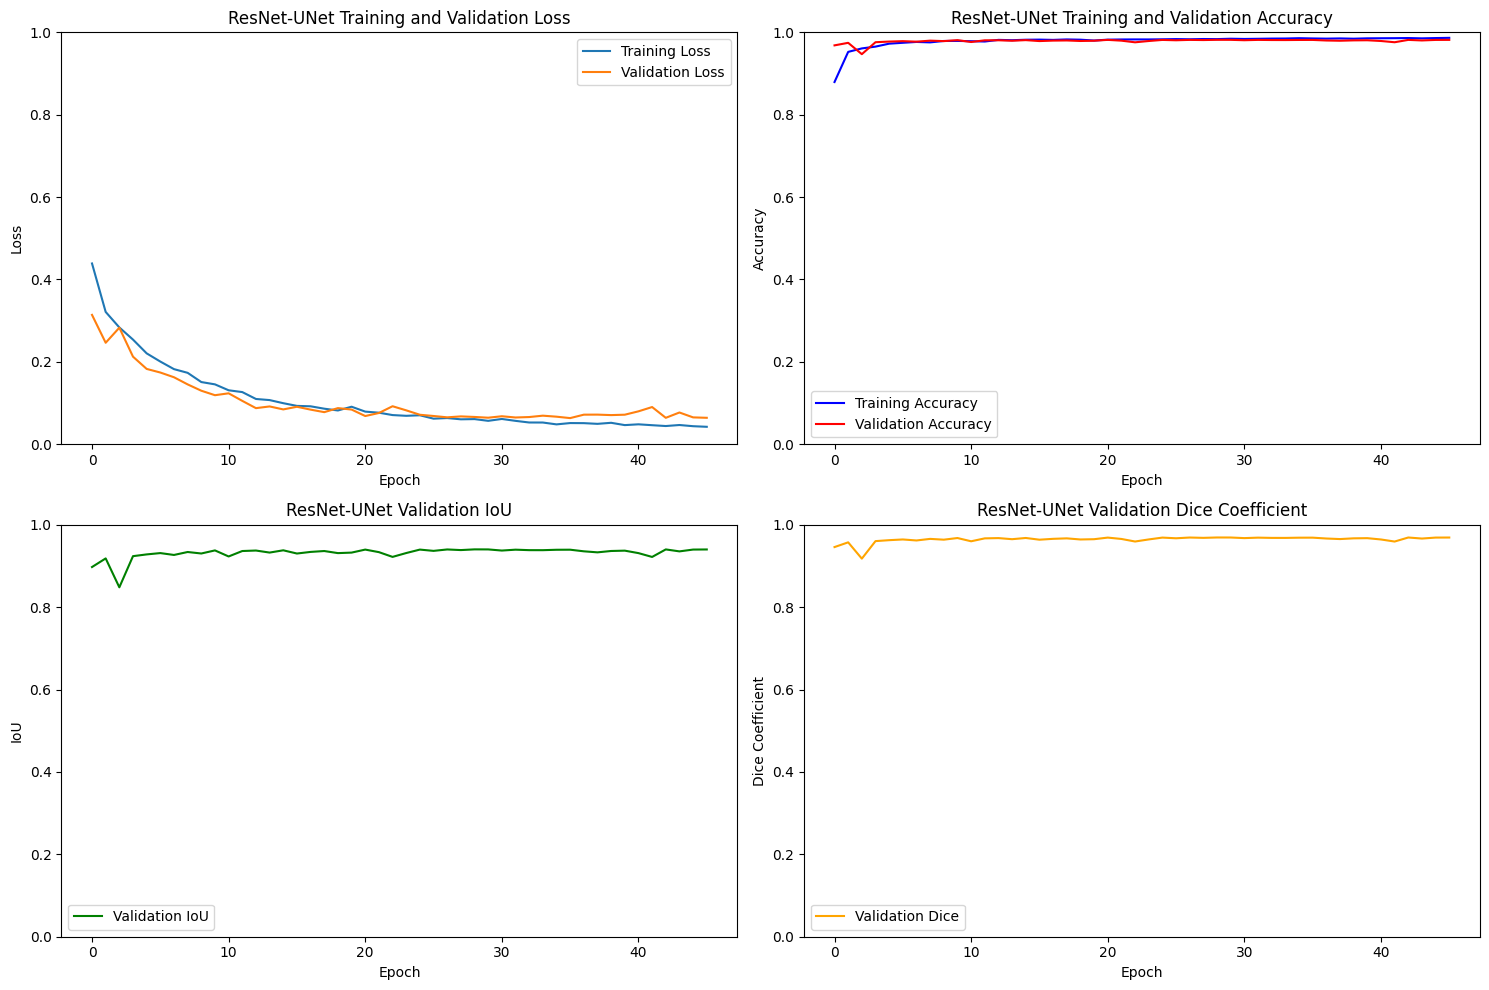

In [7]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

ax1.plot(train_losses, label='Training Loss')
ax1.plot(val_losses, label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_ylim(0, 1)
ax1.legend()
ax1.set_title('ResNet-UNet Training and Validation Loss')

ax2.plot(train_accs, label='Training Accuracy', color='blue')
ax2.plot(val_accs, label='Validation Accuracy', color='red')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1)
ax2.legend()
ax2.set_title('ResNet-UNet Training and Validation Accuracy')

ax3.plot(val_ious, label='Validation IoU', color='green')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('IoU')
ax3.set_ylim(0, 1)
ax3.legend()
ax3.set_title('ResNet-UNet Validation IoU')

ax4.plot(val_dices, label='Validation Dice', color='orange')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('Dice Coefficient')
ax4.set_ylim(0, 1)
ax4.legend()
ax4.set_title('ResNet-UNet Validation Dice Coefficient')

plt.tight_layout()
plt.savefig('PV01_ResNetUNet_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

## Test Evaluation

Loading best ResNet-UNet model for test evaluation...

Evaluating ResNet-UNet on test set...


Val batch: 100%|██████████| 97/97 [00:02<00:00, 37.81it/s]



TEST EVALUATION METRICS
Configuration: ResNet-UNet | dropout as U-Net: layer3 = 0.15, bottleneck = 0.2, decoder = 0.15
Test set processed with batch_size=1
Loss:            0.066837
IoU:             0.9355
mIoU:            0.9570
Dice Coefficient: 0.9667
Accuracy:        0.9836
Precision:       0.9671
Recall:          0.9662
F1-Score:        0.9667
Confusion matrix (pixel-level):
[[4738538   51494]
 [  52910 1514050]]


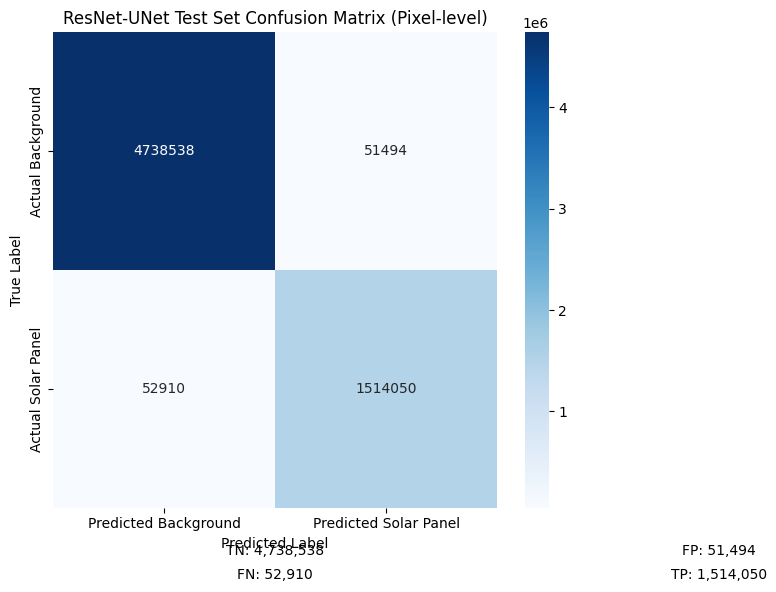

ResNet-UNet training and evaluation completed!


In [8]:
print("Loading best ResNet-UNet model for test evaluation...")
model.load_state_dict(torch.load('PV01_ResNetUNet.pth', map_location=device))
model.to(device)

print("\nEvaluating ResNet-UNet on test set...")
test_metrics = validate(model, test_loader)

print("\n" + "="*50)
print("TEST EVALUATION METRICS")
print("Configuration: ResNet-UNet | dropout as U-Net: layer3 = 0.15, bottleneck = 0.2, decoder = 0.15")
print("="*50)
print(f"Test set processed with batch_size=1")
print(f"Loss:            {test_metrics['loss']:.6f}")
print(f"IoU:             {test_metrics['iou']:.4f}")
print(f"mIoU:            {test_metrics['miou']:.4f}")
print(f"Dice Coefficient: {test_metrics['dice']:.4f}")
print(f"Accuracy:        {test_metrics['acc']:.4f}")
print(f"Precision:       {test_metrics['precision']:.4f}")
print(f"Recall:          {test_metrics['recall']:.4f}")
print(f"F1-Score:        {test_metrics['f1']:.4f}")
print("Confusion matrix (pixel-level):")
print(test_metrics["confusion"])
print("="*50)

plt.figure(figsize=(8, 6))
cm = test_metrics["confusion"]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Background', 'Predicted Solar Panel'],
            yticklabels=['Actual Background', 'Actual Solar Panel'])
plt.title('ResNet-UNet Test Set Confusion Matrix (Pixel-level)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.text(0.5, -0.1, f'TN: {cm[0,0]:,}', ha='center', transform=plt.gca().transAxes)
plt.text(1.5, -0.1, f'FP: {cm[0,1]:,}', ha='center', transform=plt.gca().transAxes)
plt.text(0.5, -0.15, f'FN: {cm[1,0]:,}', ha='center', transform=plt.gca().transAxes)
plt.text(1.5, -0.15, f'TP: {cm[1,1]:,}', ha='center', transform=plt.gca().transAxes)

plt.tight_layout()
plt.savefig('PV01_ResNetUNet_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("ResNet-UNet training and evaluation completed!")


## Test the model on images

PV01_Rooftop_Brick: 138 pairs
PV01_Rooftop_FlatConcrete: 413 pairs
PV01_Rooftop_SteelTile: 94 pairs


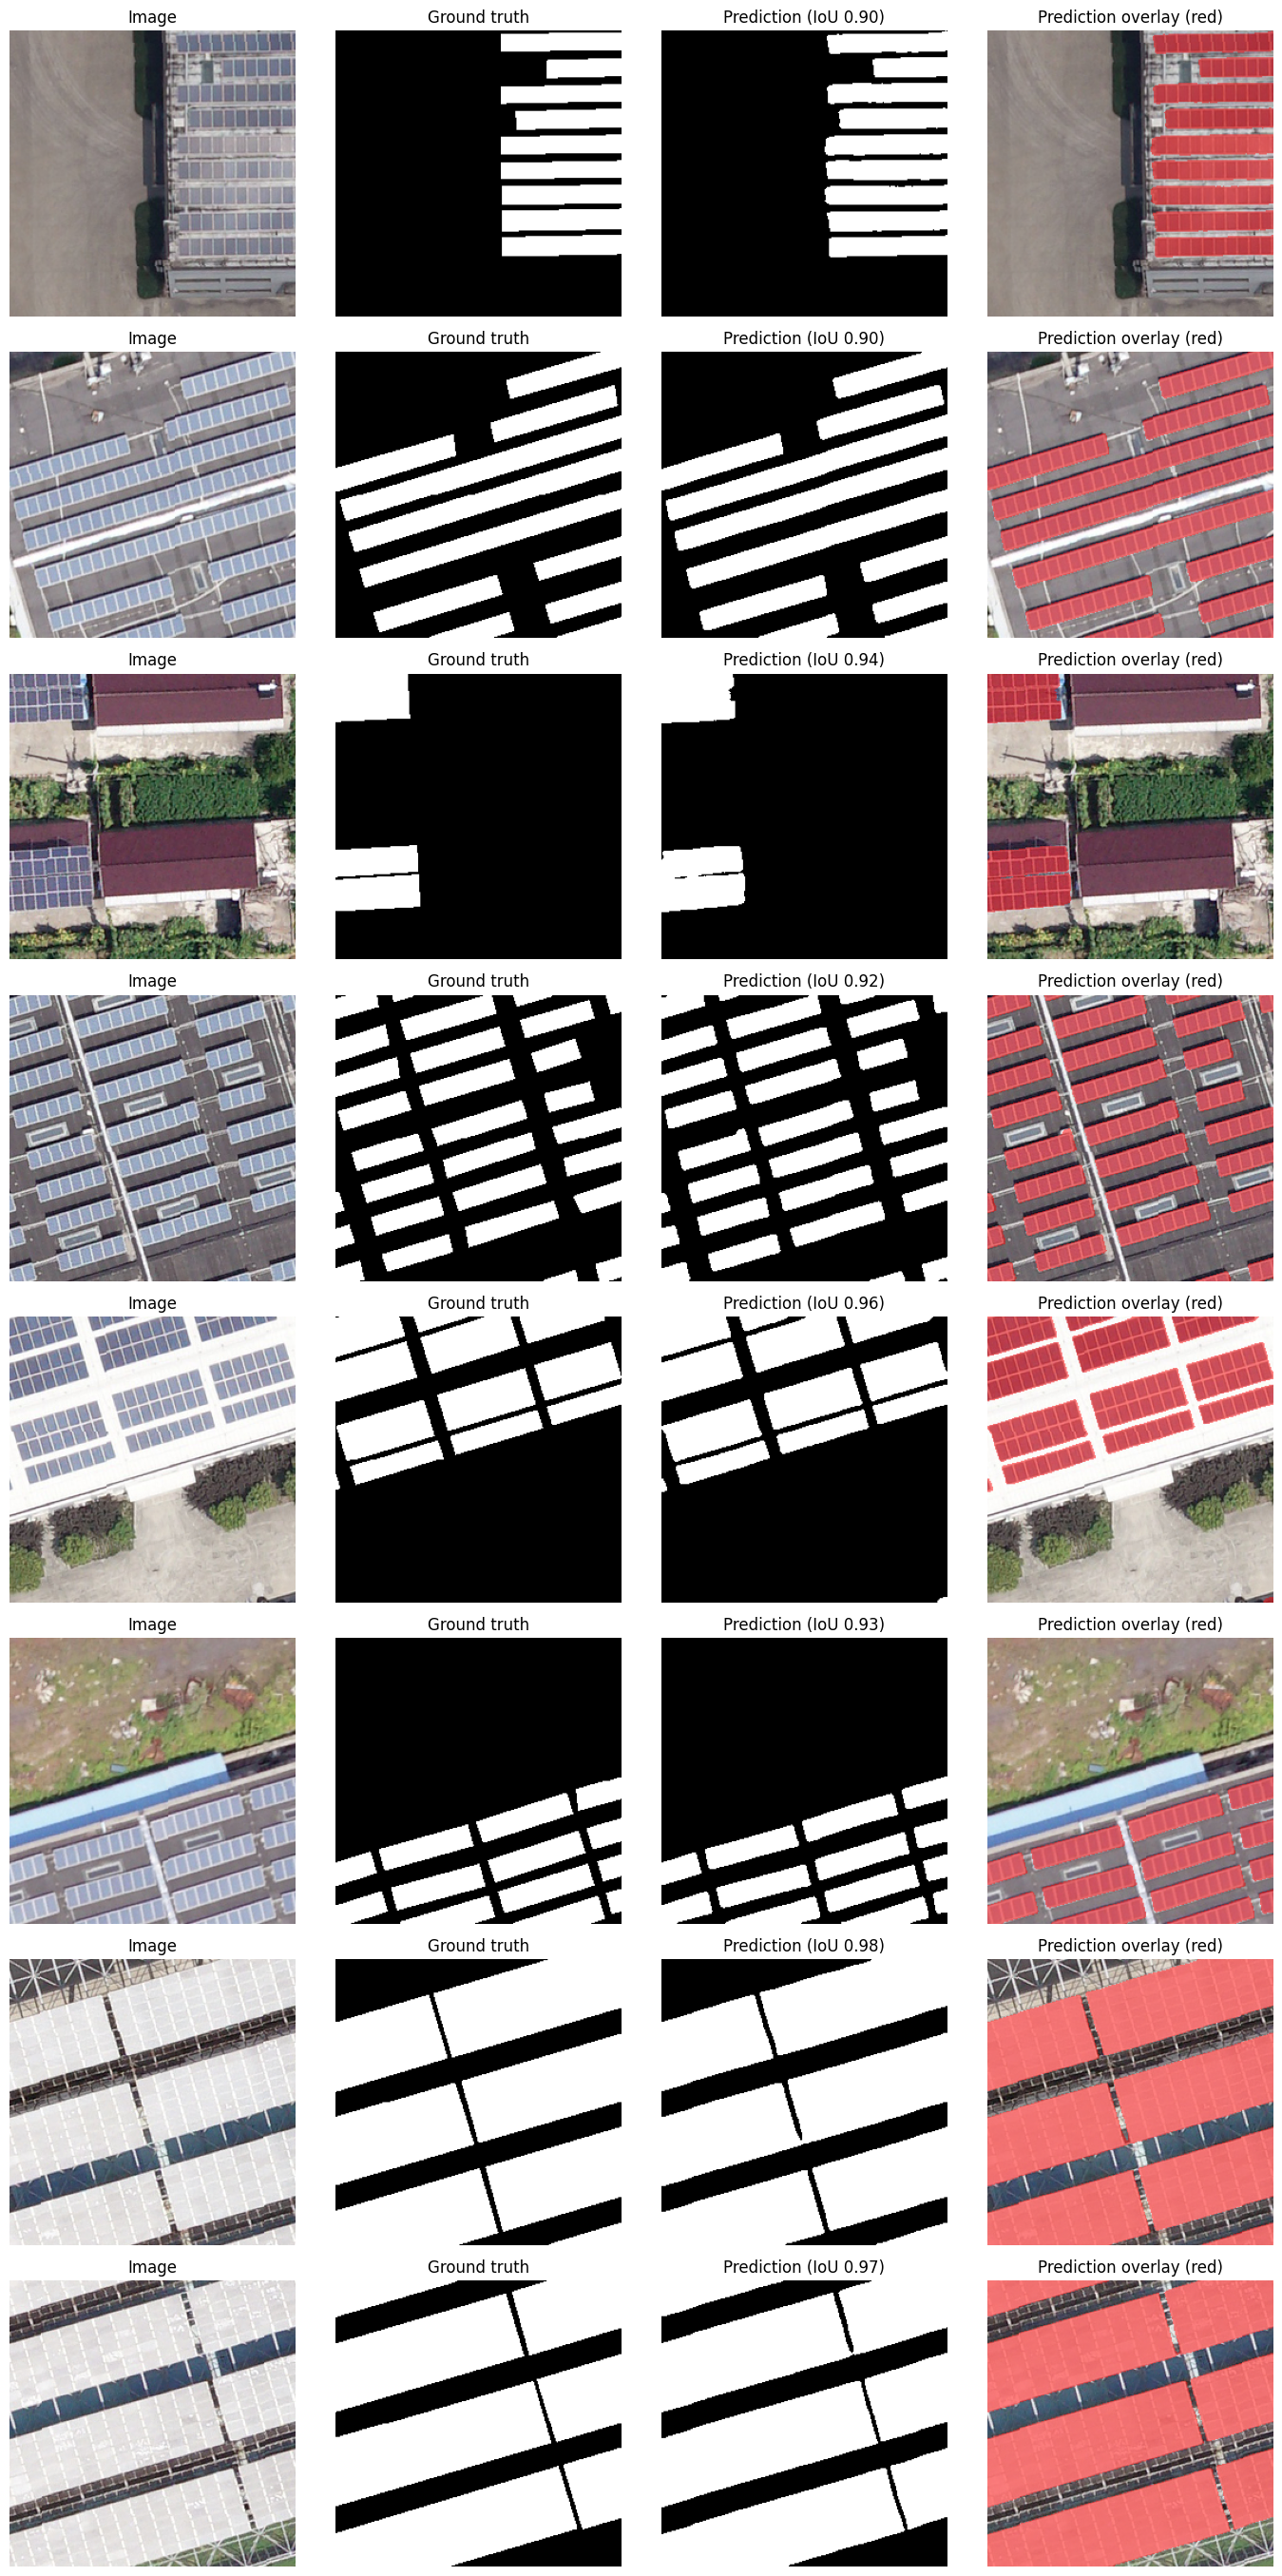

In [9]:
import random

root_dir = '/kaggle/input/datasets/huihuiiiiiiiii/pv01dataset/PV01/PV01'
IMG_SIZE = (256, 256)
BACKBONE = 'resnet34'   # must match the backbone used in training
DROPOUT = {'encoder': {'layer3': 0.15, 'layer4': 0.2}, 'decoder': 0.15}
CKPT = 'PV01_ResNetUNet.pth'

# rebuild the test set and load the best checkpoint
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
_, _, test_pairs = build_pv01_splits(root_dir, val_frac=0.15, test_frac=0.15, seed=42)
test_ds = PV01Dataset(test_pairs, transform=tf, img_size=IMG_SIZE)

net = ResNetUNet(backbone=BACKBONE, pretrained=False, in_ch=3, out_ch=1, dropout_rates=DROPOUT).to(device)
net.load_state_dict(torch.load(CKPT, map_location=device))
net.eval()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def show_predictions(n=8, seed=0, thresh=0.5):
    random.seed(seed)
    idxs = random.sample(range(len(test_ds)), n)
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.4 * n))
    for r, i in enumerate(idxs):
        img, gt = test_ds[i]
        with torch.no_grad():
            prob = torch.sigmoid(net(img.unsqueeze(0).to(device)))[0, 0].cpu()
        pred = (prob >= thresh).float()

        rgb = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        gt_np, pred_np = gt[0].numpy(), pred.numpy()

        inter = (gt_np * pred_np).sum()
        union = gt_np.sum() + pred_np.sum() - inter
        iou = inter / union if union > 0 else float('nan')

        overlay = rgb.copy()
        overlay[pred_np > 0] = 0.5 * overlay[pred_np > 0] + 0.5 * np.array([1, 0, 0])

        axes[r, 0].imshow(rgb);                  axes[r, 0].set_title("Image")
        axes[r, 1].imshow(gt_np, cmap='gray');   axes[r, 1].set_title("Ground truth")
        axes[r, 2].imshow(pred_np, cmap='gray'); axes[r, 2].set_title(f"Prediction (IoU {iou:.2f})")
        axes[r, 3].imshow(overlay);              axes[r, 3].set_title("Prediction overlay (red)")
        for a in axes[r]: a.axis('off')
    plt.tight_layout()
    plt.savefig('PV01_ResNetUNet_predictions.png', dpi=200, bbox_inches='tight')
    plt.show()

show_predictions(n=8, seed=0)
